In [27]:
import pandas as pd
import numpy as np
import math

In [28]:
#EDA stands for Exploratory Data Analysis
# remember, to make a permanent change, you have to set the dataframe equal to the function you are performing

In [48]:
df = pd.read_csv("eda_data")
df.head()

,Unnamed: 0,student_id,study_hours,attendance_pct,assignments_completed,exam_score,course_format
0,0,1,2.0,82.0,7.0,68.0,in-person
1,1,2,3.5,88.0,8.0,76.0,in-person
2,2,3,NaN,75.0,6.0,61.0,online
3,3,4,5.0,95.0,10.0,88.0,in-person
4,4,5,4.0,NaN,9.0,84.0,online


In [49]:
# Remove 'Unnamed: 0' column (the 'axis=1' means column)
df = df.drop("Unnamed: 0", axis=1)

In [50]:
df.head()

,student_id,study_hours,attendance_pct,assignments_completed,exam_score,course_format
0,1,2.0,82.0,7.0,68.0,in-person
1,2,3.5,88.0,8.0,76.0,in-person
2,3,NaN,75.0,6.0,61.0,online
3,4,5.0,95.0,10.0,88.0,in-person
4,5,4.0,NaN,9.0,84.0,online


In [51]:
# resetting the index to use 'student_id'
df = df.set_index("student_id")

In [52]:
# Data within columns and the size of the dataframe 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 1 to 20
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            19 non-null     float64
 1   attendance_pct         18 non-null     float64
 2   assignments_completed  18 non-null     float64
 3   exam_score             18 non-null     float64
 4   course_format          20 non-null     str    
dtypes: float64(4), str(1)
memory usage: 1.1 KB


In [53]:
# Obtaining the size of the data using the shape method
df.shape

(20, 5)

In [54]:
# Statistics of the numerical columns
df.describe()

,study_hours,attendance_pct,assignments_completed,exam_score
count,19.000000,18.000000,18.000000,18.000000
mean,4.394737,88.277778,8.277778,80.944444
std,1.961993,8.463107,1.637989,12.858836
min,1.500000,72.000000,5.000000,58.000000
25%,2.750000,82.250000,7.000000,70.500000
50%,4.000000,89.500000,8.500000,84.500000
75%,5.750000,95.750000,10.000000,92.250000
max,8.000000,99.000000,10.000000,98.000000


In [55]:
# to change the shape of the describe (which I like more), use this version
df.describe().T # or df.describe.transpose()

,count,mean,std,min,25%,50%,75%,max
study_hours,19.0,4.394737,1.961993,1.5,2.75,4.0,5.75,8.0
attendance_pct,18.0,88.277778,8.463107,72.0,82.25,89.5,95.75,99.0
assignments_completed,18.0,8.277778,1.637989,5.0,7.00,8.5,10.00,10.0
exam_score,18.0,80.944444,12.858836,58.0,70.50,84.5,92.25,98.0


In [56]:
#finding missing values
df.isnull().sum()

study_hours              1
attendance_pct           2
assignments_completed    2
exam_score               2
course_format            0
dtype: int64

In [57]:
df.isna().sum()

study_hours              1
attendance_pct           2
assignments_completed    2
exam_score               2
course_format            0
dtype: int64

In [58]:
# using a dictionary function to create a new dataframe consisting of measures you want
missing_summary = pd.DataFrame({"count":df.isna().sum(),
                                 "percent":df.isna().mean()*100})

In [59]:
missing_summary

,count,percent
study_hours,1,5.0
attendance_pct,2,10.0
assignments_completed,2,10.0
exam_score,2,10.0
course_format,0,0.0


In [41]:
# cleaning N/A values
# if filling income, should use Median. If ages of a similarly aged group, use Mean)
df = df.fillna(value = 0) # or df.fillna(value = -999, inplace=True)

In [42]:
df

,study_hours,attendance_pct,assignments_completed,exam_score,course_format
student_id,,,,,
1,2.0,82.0,7.0,68.0,in-person
2,3.5,88.0,8.0,76.0,in-person
3,0.0,75.0,6.0,61.0,online
4,5.0,95.0,10.0,88.0,in-person
5,4.0,0.0,9.0,84.0,online
6,6.0,97.0,10.0,93.0,in-person
7,2.5,84.0,8.0,72.0,online
8,7.0,98.0,0.0,96.0,in-person
9,3.0,80.0,7.0,70.0,online


In [60]:
df.head()

,study_hours,attendance_pct,assignments_completed,exam_score,course_format
student_id,,,,,
1,2.0,82.0,7.0,68.0,in-person
2,3.5,88.0,8.0,76.0,in-person
3,NaN,75.0,6.0,61.0,online
4,5.0,95.0,10.0,88.0,in-person
5,4.0,NaN,9.0,84.0,online


<Axes: xlabel='study_hours', ylabel='exam_score'>

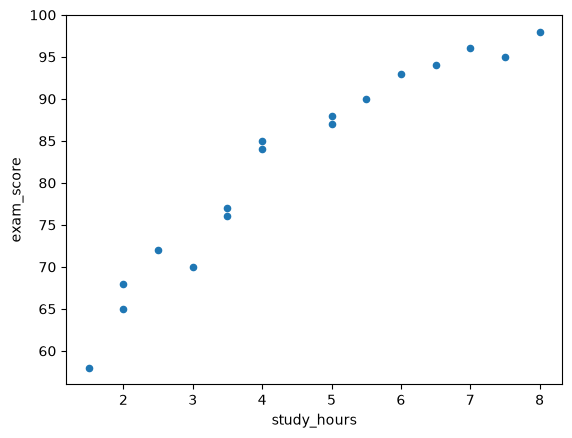

In [61]:
df.plot.scatter(x="study_hours", y="exam_score")

<Axes: ylabel='Frequency'>

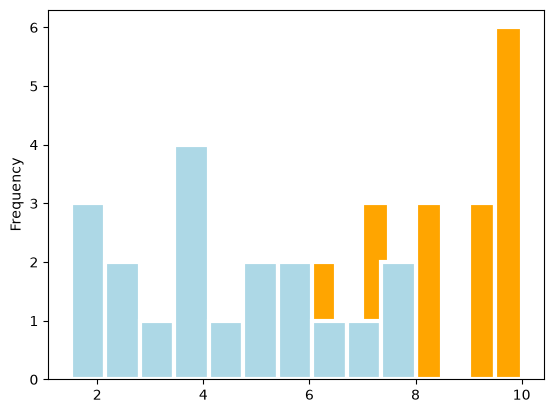

In [66]:
# making a histogram
df['assignments_completed'].plot.hist(edgecolor="white", lw=3, color="orange")
df['study_hours'].plot.hist(edgecolor="white", lw=3, color="lightblue")

<Axes: xlabel='student_id'>

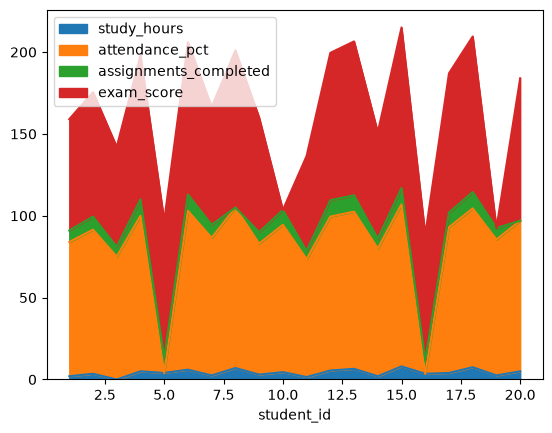

In [67]:
# Area plot
df.plot.area()

<Axes: xlabel='student_id'>

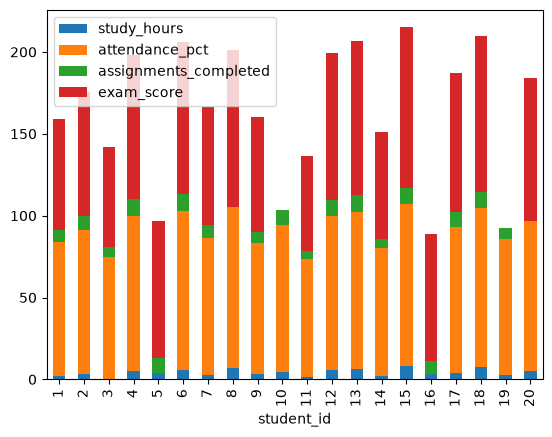

In [68]:
df.plot.bar(stacked=True)

<Axes: xlabel='student_id'>

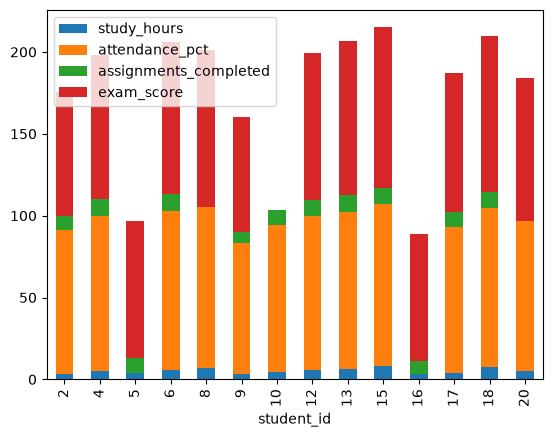

In [70]:
df[df["study_hours"]>=3].plot.bar(stacked=True)